**Ejecicio de clase**
Analiza la normalidad en la variable avg_sleep_hours del dataset:

https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance


- Calcula la media, mediana y desviación típica.
- Calcula el sesgo, la curtosis, y comenta el resultado.
- Dibuja el histograma, y sobre el la distribución normal teórica.
- Realiza el test Shapiro-Wilk y comenta el resultado.
- Dibuja el gráfico Q-Q, y comenta el resultado.
- Recomienda una transformación (o no).



In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import kagglehub
from scipy.stats import shapiro, normaltest, probplot, boxcox

# Download latest version
path = kagglehub.dataset_download("aamir28/student-sleep-screen-time-and-academic-performance")
df = pd.read_csv(f"{path}/student_sleep_screen_time_academic_performance.csv")
df.shape


#Análisis básico de la variable "avg_sleep_hours"
print("Análisis básico de la variable 'avg_sleep_hours_weekday'")
print(df['avg_sleep_hours_weekday'].describe())
print("\nValores nulos en la variable 'avg_sleep_hours_weekday':", df['avg_sleep_hours_weekday'].isnull().sum())



Análisis básico de la variable 'avg_sleep_hours_weekday'
count    500.000000
mean       6.608200
std        1.435784
min        1.500000
25%        5.700000
50%        6.600000
75%        7.700000
max       10.500000
Name: avg_sleep_hours_weekday, dtype: float64

Valores nulos en la variable 'avg_sleep_hours_weekday': 0


No hay valores nulos, la media y la mediana son muy parecidas, lo que nos indica que es posible que no haya sesgo importante.

**Sesgo y curtosis**

In [11]:
# Calculamos el sesgo y la curtosis de la variable "avg_sleep_hours_weekday"
skewness = stats.skew(df['avg_sleep_hours_weekday'].dropna())
kurtosis = stats.kurtosis(df['avg_sleep_hours_weekday'].dropna())
print(f"\nSesgo de la variable 'avg_sleep_hours_weekday': {skewness}")
print(f"Curtosis de la variable 'avg_sleep_hours_weekday': {kurtosis}")
                                                            


Sesgo de la variable 'avg_sleep_hours_weekday': -0.2833226376481837
Curtosis de la variable 'avg_sleep_hours_weekday': -0.09990807612270869


Efectivamente, el sesgo es muy pequeño = |-0.28| < 0.5
La curtosis es cercana a 0 (Mesocúrtica normal)

**Histograma Q-Q y Test Shapiro-Wilk**

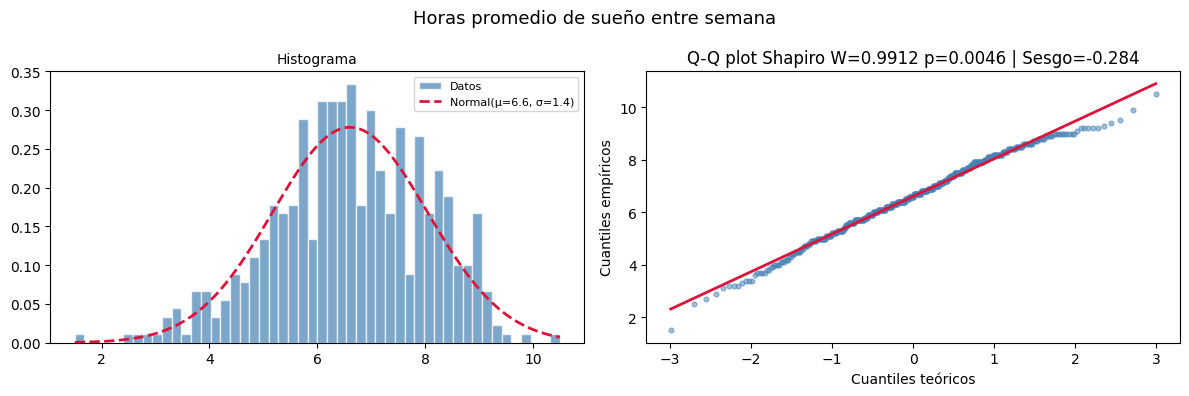

In [ ]:


def panel_normalidad(serie, nombre=''):
    """Combina histograma + KDE y Q-Q plot para diagnóstico completo de normalidad."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle("Horas promedio de sueño entre semana", fontsize=13)
    
    # Histograma con curva KDE y normal ajustada
    mu, sigma = serie.mean(), serie.std()
    axes[0].hist(serie, bins=50
                 , color='steelblue', edgecolor='white',
                 alpha=0.7, density=True, label='Datos')
    
    x = np.linspace(serie.min(), serie.max(), 300)
    axes[0].plot(x, stats.norm.pdf(x, mu, sigma), 'crimson',
                 linewidth=2, linestyle='--', label=f'Normal(μ={mu:.1f}, σ={sigma:.1f})')
    axes[0].set_title(f'Histograma', fontsize=10)
    axes[0].legend(fontsize=8)
    
    # Q-Q plot
    res = probplot(serie, dist='norm')
    teoricos, empiricos = res[0]
    slope, intercept, r = res[1]
    axes[1].scatter(teoricos, empiricos, s=12, alpha=0.5, color='steelblue')
    x_line = np.array([teoricos.min(), teoricos.max()])
    axes[1].plot(x_line, slope * x_line + intercept, 'crimson', linewidth=2)
    
    W, p = shapiro(serie[:500] if len(serie) > 500 else serie)
    skew = serie.skew()
    axes[1].set_title(f'Q-Q plot Shapiro W={W:.4f} p={p:.4f} | Sesgo={skew:.3f}')
    axes[1].set_xlabel('Cuantiles teóricos')
    axes[1].set_ylabel('Cuantiles empíricos')
    
    plt.tight_layout()
    plt.show()


panel_normalidad(df['avg_sleep_hours_weekday'].dropna(), 'Horas promedio de sueño entre semana')

**Histograma**

La normal ajustada (μ = 6.6, σ = 1.4) describe bien la forma general.
Los “dientes” (huecos hacia 5.6 y 7.6 h) seguramente salen de que los datos están redondeados, por ejemplo a cuartos o medias horas, y los bins no coinciden con esos escalones.

**Shapiro-Wilk (W = 0.9912, p = 0.0046)**

- Con α = 0.05 el test rechaza la normalidad. Pero W = 0.991 está muy cerca de 1, y la desviación es pequeña.
- Con muestras grandes (aquí parecen unos cientos de datos), Shapiro detecta como “significativas” desviaciones mínimas. Pesa más el aspecto de los gráficos que el p-valor.

**Q-Q plot**

- El centro, entre −2 y +2, se ajusta muy bien a la recta.
- Cola izquierda: los puntos quedan por debajo de la recta. Los valores bajos son más extremos de lo que predice la normal, es decir, la cola es más larga.
- Cola derecha: los puntos también quedan por debajo. Los valores altos se quedan cortos: el máximo es ~10.5 cuando la normal esperaría ~11. Que la cola izquierda sea larga y la derecha corta es justo la huella del sesgo negativo.
- Hay un tramo plano en torno a 9–9.2 h: muchos valores repetidos. Podría ser redondeo, un límite en el cuestionario o gente que responde “9” por defecto. 

**Recomendación de transformación**



In [18]:
from sklearn.preprocessing import PowerTransformer

def recomendar_transformacion(serie, nombre=''):
    """Evalúa la normalidad y recomienda la transformación más adecuada."""
    sesgo = serie.skew()
    tiene_ceros = (serie == 0).any()
    tiene_negativos = (serie < 0).any()
    
    print(f"Variable: {nombre or serie.name}")
    print(f"  Sesgo original: {sesgo:.3f}")
    print(f"  Valores cero: {tiene_ceros}  |  Valores negativos: {tiene_negativos}")
    
    if abs(sesgo) < 0.5:
        print("  → Distribución suficientemente simétrica. No es necesario transformar.")
    elif tiene_negativos:
        print("  → Recomendación: Yeo-Johnson (acepta negativos)")
        pt = PowerTransformer(method='yeo-johnson')
        transformada = pt.fit_transform(serie.values.reshape(-1, 1)).ravel()
        print(f"  → Sesgo tras Yeo-Johnson: {stats.skew(transformada):.3f}  (λ={pt.lambdas_[0]:.3f})")
    elif tiene_ceros:
        print("  → Recomendación: log(x+1) o Yeo-Johnson (hay ceros, Box-Cox no aplica)")
        transformada = np.log1p(serie)
        print(f"  → Sesgo tras log1p: {stats.skew(transformada):.3f}")
    else:
        print("  → Recomendación: Box-Cox (todos los valores son positivos)")
        transformada, lam = boxcox(serie.values)
        print(f"  → Sesgo tras Box-Cox: {stats.skew(transformada):.3f}  (λ={lam:.3f})")
    print()

recomendar_transformacion(df['avg_sleep_hours_weekday'].dropna(), 'Horas promedio de sueño entre semana')


Variable: Horas promedio de sueño entre semana
  Sesgo original: -0.284
  Valores cero: False  |  Valores negativos: False
  → Distribución suficientemente simétrica. No es necesario transformar.

